# Predicting students’ final grades with linear regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})
print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

pandas: 2.3.3 | scikit-learn: 1.5.2


## (a) Data exploration and preprocessing
### (i) Load and inspect the data

In [2]:
raw = pd.read_csv('student-mat.csv', sep=';')
print('Dataset shape:', raw.shape)
display(raw.head())
raw.info()
display(raw.describe())
print('Missing values in the original data:')
display(raw.isna().sum().to_frame('missing_count'))

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


Missing values in the original data:


,missing_count
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


### (ii) Select and transform the variables

In [3]:
selected = ['age', 'studytime', 'schoolsup', 'goout', 'Dalc',
            'Walc', 'health', 'absences', 'G3']
data = raw[selected].copy()
data['schoolsup'] = data['schoolsup'].map({'no': 0, 'yes': 1})
data['alc'] = (data['Dalc'] + data['Walc']) / 2
data = data.drop(columns=['Dalc', 'Walc'])
features = ['age', 'studytime', 'schoolsup', 'goout', 'health', 'absences', 'alc']
data = data[features + ['G3']]
X = data[features]
y = data['G3']
print('First five rows after preprocessing:')
display(data.head())
print('Missing values after preprocessing:')
display(data.isna().sum().to_frame('missing_count'))
display(data.describe())

First five rows after preprocessing:


,age,studytime,schoolsup,goout,health,absences,alc,G3
0,18,2,1,4,3,6,1.0,6
1,17,2,0,3,3,4,1.0,6
2,15,2,1,2,3,10,2.5,10
3,15,3,0,2,5,2,1.0,15
4,16,2,0,2,5,4,1.5,10


Missing values after preprocessing:


,missing_count
age,0
studytime,0
schoolsup,0
goout,0
health,0
absences,0
alc,0
G3,0


,age,studytime,schoolsup,goout,health,absences,alc,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.035443,0.129114,3.108861,3.554430,5.708861,1.886076,10.415190
std,1.276043,0.839240,0.335751,1.113278,1.390303,8.003096,0.992195,4.581443
min,15.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000
25%,16.000000,1.000000,0.000000,2.000000,3.000000,0.000000,1.000000,8.000000
50%,17.000000,2.000000,0.000000,3.000000,4.000000,4.000000,1.500000,11.000000
75%,18.000000,2.000000,0.000000,4.000000,5.000000,8.000000,2.500000,14.000000
max,22.000000,4.000000,1.000000,5.000000,5.000000,75.000000,5.000000,20.000000


The mathematics dataset has 395 rows. There are no missing values in the selected variables, so I did not need to fill in or remove missing observations.

### (iii) Outliers using the IQR method
For each predictor, I calculated $IQR=Q_3-Q_1$. I flagged values below $Q_1-1.5IQR$ or above $Q_3+1.5IQR$.

,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
age,16.0,18.0,2.0,13.00,21.00,1
studytime,1.0,2.0,1.0,-0.50,3.50,27
schoolsup,0.0,0.0,0.0,0.00,0.00,51
goout,2.0,4.0,2.0,-1.00,7.00,0
health,3.0,5.0,2.0,0.00,8.00,0
absences,0.0,8.0,8.0,-12.00,20.00,15
alc,1.0,2.5,1.5,-1.25,4.75,9


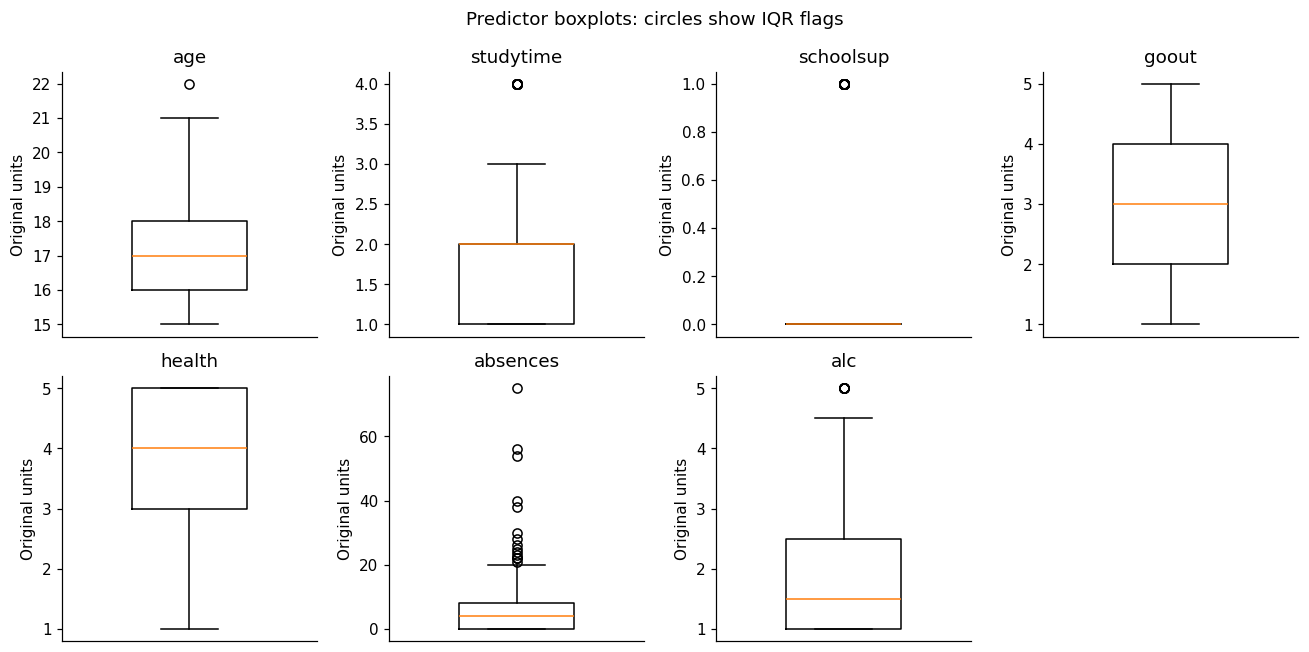

In [4]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_mask = X.lt(lower) | X.gt(upper)
outliers = pd.DataFrame({'Q1': q1, 'Q3': q3, 'IQR': iqr,
                         'lower_bound': lower, 'upper_bound': upper,
                         'outlier_count': outlier_mask.sum()})
display(outliers)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, feature in zip(axes.flat, features):
    ax.boxplot(X[feature], widths=0.45)
    ax.set_title(feature)
    ax.set_xticks([])
    ax.set_ylabel('Original units')
axes.flat[-1].axis('off')
fig.suptitle('Predictor boxplots: circles show IQR flags')
fig.tight_layout()
plt.show()

The numbers of flagged observations are 1 for age, 27 for studytime, 51 for schoolsup, 0 for goout, 0 for health, 15 for absences, and 9 for alc.

I kept these observations. For `schoolsup`, both quartiles are 0, so its IQR is 0 and every value of 1 is flagged. These are valid “yes” responses, not recording errors. 
The IQR rule is also limited for studytime, goout, health, and alc because they are ordinal ratings, and alc is an average of two ordinal ratings. A flag alone is not enough reason to delete a student’s record.

### (iv) Standardization and PCA

,component,explained_variance_ratio
0,PC1,0.236757
1,PC2,0.171366
2,PC3,0.151961
3,PC4,0.140408
4,PC5,0.126730
5,PC6,0.094774
6,PC7,0.078004


,PC1,PC2
age,0.381940,0.589260
studytime,-0.329734,0.385671
schoolsup,-0.248184,-0.464202
goout,0.493755,-0.139613
health,0.080545,-0.400925
absences,0.280106,0.182798
alc,0.595871,-0.273677


PC1 largest absolute weights:


alc      0.595871
goout    0.493755
age      0.381940
Name: PC1, dtype: float64

PC2 largest absolute weights:


age          0.589260
schoolsup    0.464202
health       0.400925
Name: PC2, dtype: float64

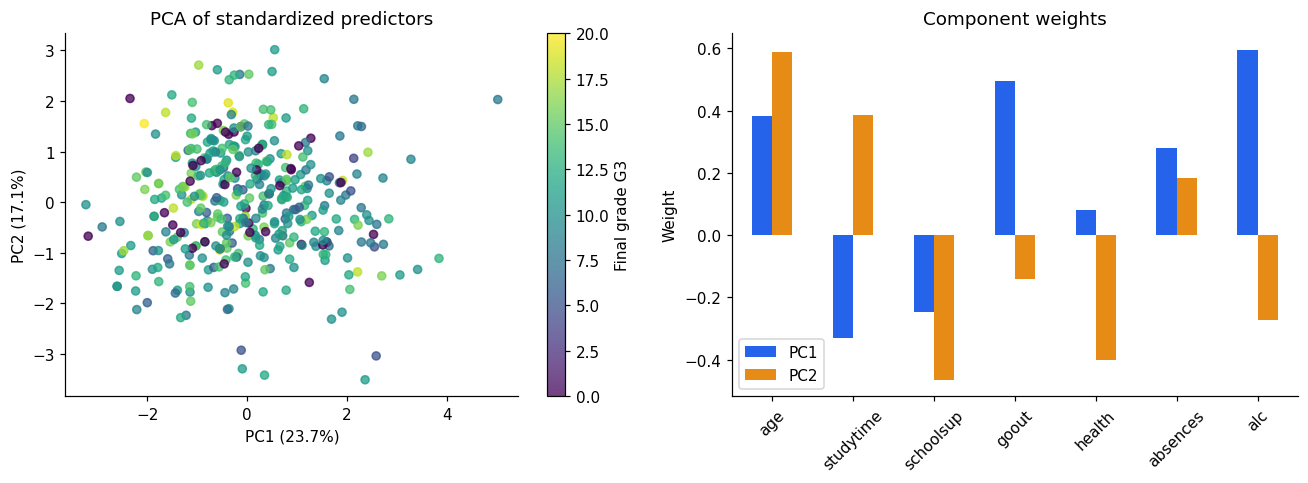

In [5]:
exploration_scaler = StandardScaler()
X_exploration_scaled = exploration_scaler.fit_transform(X)
pca = PCA()
pcs = pca.fit_transform(X_exploration_scaled)

explained = pd.DataFrame({
    'component': [f'PC{i+1}' for i in range(len(features))],
    'explained_variance_ratio': pca.explained_variance_ratio_
})
display(explained)
# These are component weights, often called loadings in this context.
loadings = pd.DataFrame(pca.components_[:2].T,
                        index=features, columns=['PC1', 'PC2'])
display(loadings)
for pc in ['PC1', 'PC2']:
    print(pc, 'largest absolute weights:')
    display(loadings[pc].abs().sort_values(ascending=False).head(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
points = axes[0].scatter(pcs[:, 0], pcs[:, 1], c=y, cmap='viridis',
                         vmin=0, vmax=20, alpha=0.75, s=28)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('PCA of standardized predictors')
fig.colorbar(points, ax=axes[0], label='Final grade G3')
loadings.plot.bar(ax=axes[1], color=['#2563eb', '#e58b16'])
axes[1].set_title('Component weights')
axes[1].set_ylabel('Weight')
axes[1].tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

PC1 explains about **23.68%** of the predictor variance, and PC2 explains about **17.14%**. Together they explain **40.81%**, so the two-dimensional plot leaves out a substantial amount of information.

The largest absolute PC1 weights are **alc (0.596)**, **goout (0.494)**, and **age (0.382)**. For PC2, they are **age (0.589)**, **schoolsup (−0.464)**, and **health (−0.401)**. I used absolute values to judge contribution because a large negative weight can be just as important as a large positive one. PCA signs can flip without changing the result.

The grades overlap in the scatterplot rather than forming clearly separated groups. Also, PCA explains variation in the predictors; it does not directly find the directions that best predict grades.

## (b) Linear regression
### (i) Split and standardize

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=552
)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=features, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=features, index=X_test.index)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Standardized training predictors, first five rows:')
display(X_train_scaled.head())

Training rows: 316
Testing rows: 79
Standardized training predictors, first five rows:


,age,studytime,schoolsup,goout,health,absences,alc
125,-1.323751,-1.290019,2.422719,1.724515,1.024259,-0.689096,0.668590
99,-0.543331,1.073147,2.422719,1.724515,-0.401582,-0.689096,-0.877321
163,0.237090,-1.290019,-0.412759,-0.113417,-1.114502,-0.445250,0.668590
128,1.017510,-1.290019,-0.412759,-0.113417,0.311339,-0.689096,-0.362017
55,-0.543331,-0.108436,-0.412759,0.805549,-1.114502,0.286287,-0.877321


### (ii)–(iii) Fit and evaluate the three models
Smaller MAE and RMSE are better, while larger $R^2$ is better. RMSE gives larger errors more weight than MAE.

In [7]:
models = {
    'Linear regression': LinearRegression(),
    'Ridge': Ridge(alpha=0.1),
    'Lasso': Lasso(alpha=0.1, max_iter=10000)
}
predictions = {}
rows = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    predictions[name] = pred
    rows.append({'Model': name,
                 'MAE': mean_absolute_error(y_test, pred),
                 'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
                 'R2': r2_score(y_test, pred)})
metrics = pd.DataFrame(rows).set_index('Model')
display(metrics.round(6))
print('Best MAE:', metrics['MAE'].idxmin())
print('Best RMSE:', metrics['RMSE'].idxmin())
print('Best R2:', metrics['R2'].idxmax())
# A simple reference model always predicts the training-set mean.
baseline = np.full(len(y_test), y_train.mean())
print('Training-mean baseline:')
print(f'MAE = {mean_absolute_error(y_test, baseline):.6f}, '
      f'RMSE = {np.sqrt(mean_squared_error(y_test, baseline)):.6f}, '
      f'R2 = {r2_score(y_test, baseline):.6f}')

,MAE,RMSE,R2
Model,,,
Linear regression,3.418009,4.755812,0.028177
Ridge,3.418064,4.755860,0.028157
Lasso,3.447338,4.794612,0.012255


Best MAE: Linear regression
Best RMSE: Linear regression
Best R2: Linear regression
Training-mean baseline:
MAE = 3.598702, RMSE = 4.925535, R2 = -0.042425


Ordinary linear regression performs best on all three metrics, with **MAE = 3.4180**, **RMSE = 4.7558**, and **R² = 0.02818**. Ridge is almost identical, and Lasso is slightly worse. The difference between ordinary regression and Ridge is too small to claim a meaningful advantage from this one split.

### (iv) Interpreting R²
The test R² values are about **0.0282 for linear regression**, **0.0282 for Ridge**, and **0.0123 for Lasso**. On this test set, the models explain only about **2.82%, 2.82%, and 1.23%** of the variation in G3, respectively. These are weak results. R² is not classification accuracy, and a low R² does not mean a predictor has no relationship with the outcome.

For context, R² compares squared prediction error with the error from predicting the test-set mean. A deployable constant baseline instead uses the training-set mean; I reported that baseline separately above.

### (v) Coefficients and intercepts
Because the predictors are standardized, a coefficient represents the predicted change in G3 for a one-training-standard-deviation increase in that predictor, holding the others fixed.

In [8]:
coefficients = pd.DataFrame(
    {name: model.coef_ for name, model in models.items()}, index=features
)
coefficient_table = pd.concat([
    coefficients,
    pd.DataFrame({name: [model.intercept_] for name, model in models.items()},
                 index=['Intercept'])
])
display(coefficient_table.round(6))
# Convert the binary schoolsup coefficient to the full no-to-yes contrast.
schoolsup_sd = scaler.scale_[features.index('schoolsup')]
print('OLS predicted difference for schoolsup yes vs no:',
      round(coefficients.loc['schoolsup', 'Linear regression'] / schoolsup_sd, 4))

,Linear regression,Ridge,Lasso
age,-0.785327,-0.784976,-0.630916
studytime,0.449134,0.448974,0.351270
schoolsup,-0.717780,-0.717459,-0.570052
goout,-0.570108,-0.569917,-0.477690
health,-0.245802,-0.245702,-0.141941
absences,0.197840,0.197726,0.070762
alc,0.036301,0.036145,-0.000000
Intercept,10.613924,10.613924,10.613924


OLS predicted difference for schoolsup yes vs no: -2.0353


### (vi) Relationships with G3
Using the ordinary linear regression coefficients, and holding the other predictors fixed:

| Predictor | Coefficient | Interpretation |
|---|---:|---|
| age | −0.7853 | Older students tend to have lower predicted grades. |
| studytime | +0.4491 | More study time is associated with higher predicted grades. |
| schoolsup | −0.7178 | Students receiving extra school support have lower predicted grades in this model. |
| goout | −0.5701 | Going out more is associated with lower predicted grades. |
| health | −0.2458 | Higher health ratings have a small negative association. |
| absences | +0.1978 | Absences have a small positive association after controlling for the other variables. |
| alc | +0.0363 | Average alcohol consumption has a very small positive coefficient. |

These coefficients describe **associations, not causes**. For example, students who are already struggling may be more likely to receive school support, so the negative coefficient does not show that support causes lower grades. Similarly, the absences and alcohol coefficients do not show that missing school or drinking improves grades. These signs could reflect other variables, sampling variation, or limitations of the linear model. I did not test whether the coefficients are statistically significant.

The schoolsup coefficient above is for a one-standard-deviation increase in the encoded variable, not the complete change from no to yes. The code also reports that full contrast. Studytime and several other variables are ordinal ratings, so this model assumes equal spacing between their levels.

The intercept is about **10.6139** for all three models. It is the predicted grade when every standardized predictor is zero, meaning each original predictor is at its training-set mean. That combination does not have to describe an actual student.

### Reqired in Expected Output: Residual analysis
I defined residuals as actual grade minus predicted grade. A good fit would have residuals scattered around zero without a clear pattern.

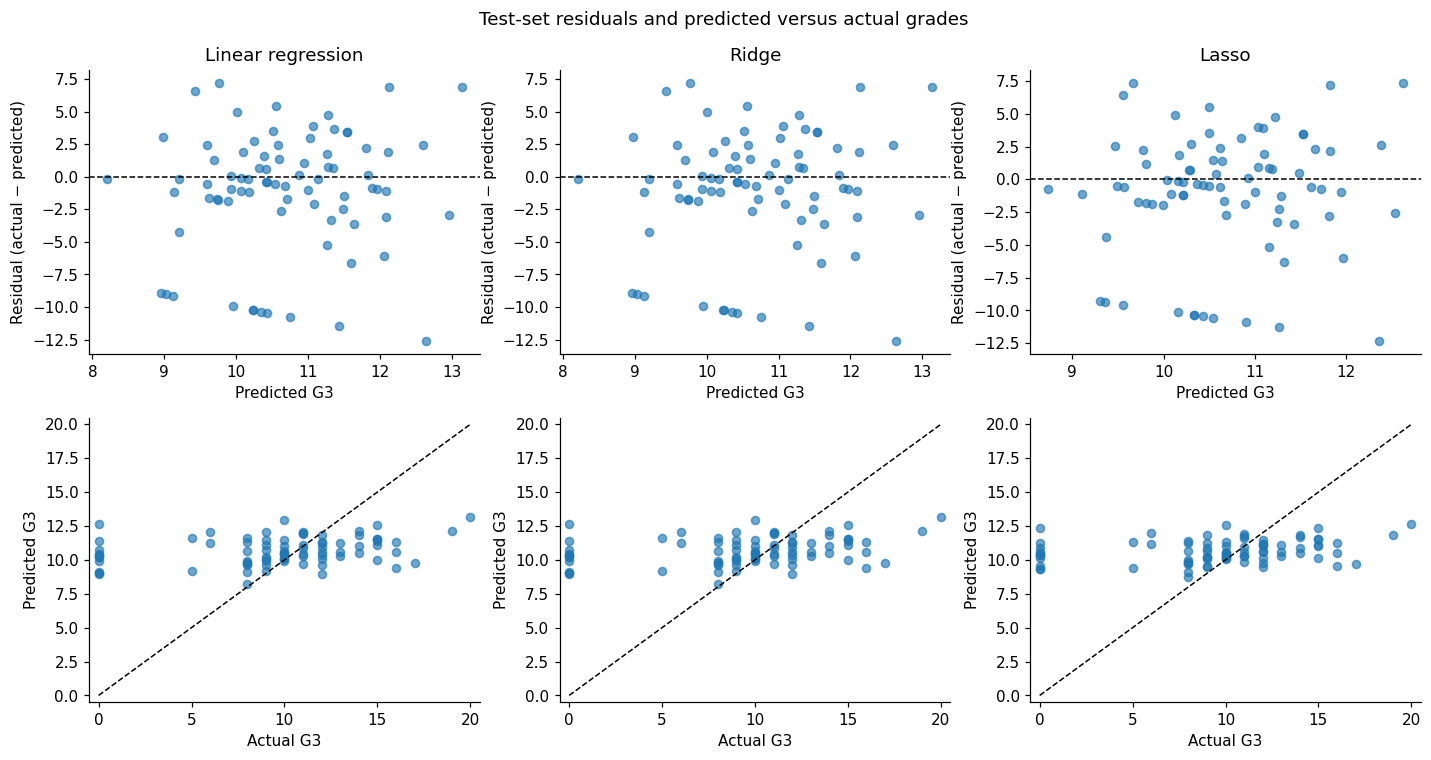

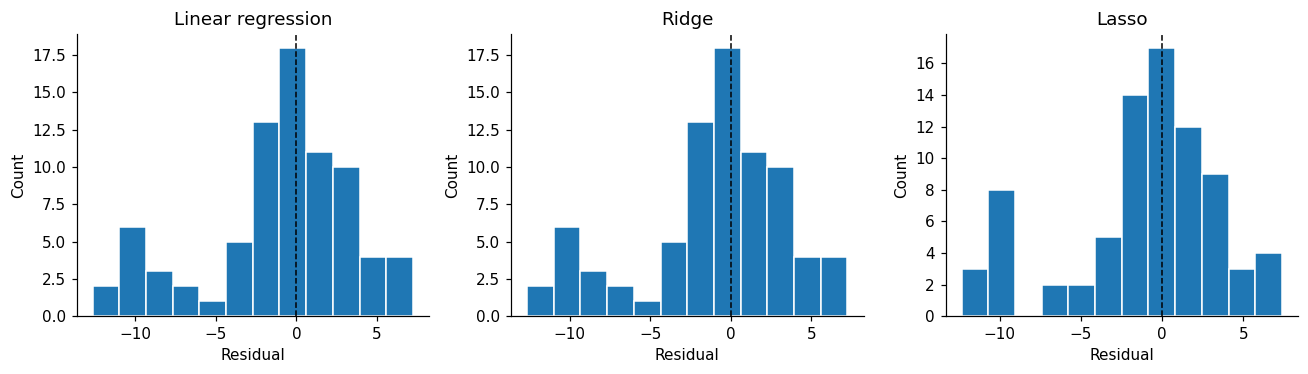

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, (name, pred) in enumerate(predictions.items()):
    residuals = y_test.to_numpy() - pred
    axes[0, col].scatter(pred, residuals, alpha=0.65, s=28)
    axes[0, col].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel('Predicted G3')
    axes[0, col].set_ylabel('Residual (actual − predicted)')
    axes[1, col].scatter(y_test, pred, alpha=0.65, s=28)
    axes[1, col].plot([0, 20], [0, 20], 'k--', linewidth=1)
    axes[1, col].set_xlim(-0.5, 20.5)
    axes[1, col].set_ylim(-0.5, 20.5)
    axes[1, col].set_xlabel('Actual G3')
    axes[1, col].set_ylabel('Predicted G3')
fig.suptitle('Test-set residuals and predicted versus actual grades')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.hist(y_test.to_numpy() - pred, bins=12, edgecolor='white')
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel('Residual')
    ax.set_ylabel('Count')
fig.tight_layout()
plt.show()

The predictions are concentrated in a relatively narrow range compared with the actual grades. In particular, students with grades near zero have large negative residuals, meaning the models overpredict their grades. The models struggle to capture the full range of outcomes, which agrees with the low test R² values.

### (vii) Comparing regularization methods
Ordinary regression minimizes the sum of squared errors. Ridge adds an L2 penalty, based on the sum of squared coefficients, which shrinks coefficients toward zero. Lasso adds an L1 penalty, based on the sum of absolute coefficients, and can set coefficients exactly to zero.

At alpha = 0.1, Ridge barely changes the coefficients or test results. Lasso shrinks the coefficients more noticeably and sets **alc to zero**, but it has slightly worse test errors. This suggests that alcohol consumption adds little to this particular Lasso fit once the other variables are included. It does not prove the variable is irrelevant in every model or population.

Overall, regularization does not improve performance on this split. The seven selected features have limited predictive power in these linear models. I would not conclude from this alone that the entire dataset is uninformative; the assignment leaves out other variables that might help. Also, scikit-learn uses different objective normalizations for Ridge and Lasso, so the same numerical alpha does not mean equally strong regularization.

### (viii) What happens if alpha increases?
Increasing alpha makes the penalty stronger. Ridge coefficients generally shrink further toward zero, while Lasso may remove more predictors. A moderate increase could improve test MAE, RMSE, and R² if it reduces overfitting. However, too much regularization can cause underfitting, increasing test MAE and RMSE and lowering R². The effect on test metrics is not necessarily monotonic.

At very large alpha, the predictions approach the training-set mean because the coefficients approach zero and the intercept is not penalized. The resulting test R² can be negative. I would choose alpha using cross-validation within the training set rather than repeatedly selecting it using the test set.

### (ix) Possible feature engineering improvements
I would try the following and check whether they improve cross-validation results:

- **Transform absences:** `log1p(absences)` could reduce the influence of a few very large absence counts. An indicator for any absence could also capture a different pattern at zero.
- **Add nonlinear terms:** squared terms for age or studytime could model relationships that are not straight lines.
- **Add interactions:** studytime × schoolsup or studytime × absences could allow the effect of studying to depend on support or attendance.
- **Encode ordinal levels separately:** one-hot encoding studytime, goout, or health would avoid assuming equal effects for each one-level increase.
- **Reconsider the alcohol average:** in an extension beyond the required model, I would compare separate workday and weekend alcohol variables with their average, since averaging loses information.
- **Use additional information if available at prediction time:** previous failures, parental education, or earlier grades G1 and G2 might help. G1 and G2 should only be used if those grades are already known when the prediction is made; they would not be appropriate for a prediction before the school year begins.